# **Projet — Stress hydrique dans les forêts du Valais Central**

<i>Basile Meichtry, d'après le cours de Géoinformatique II, UNIL</i>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<i>10 novembre 2026</i>

Ce notebook a pour objectif de documenter le projet, en présentant la méthode employée et les résultats obtenus.  
<br><br>
### **Question de recherche**

Peut-on prédire le stress hydrique des surfaces forestières du Valais central en 2018 à partir du relief et des caractéristiques de l'urbanisation environnante, sans utiliser de données climatiques ?

### **Contexte**
Le Valais central est particulièrement exposé à la sécheresse en raison de son climat intra-alpin. Le stress hydrique chez les arbres peut limiter leur activité photosynthétique. Le rapport entre évapotranspiration réelle et évapotranspiration potentielle (ET/ETp) permet d'évaluer cette contrainte: une valeur inférieure à 80% peut indiquer des conditions de sécheresse affectant la végétation.

Plusieurs facteurs pourraient influencer la répartition spatiale de cet indice. L'urbanisation, notamment par l'imperméabilisation des sols et l'effet d'îlot de chaleur urbain, pourrait modifier la disponibilité en eau pour les forêts. Le relief, à travers l'altitude et la pente, peut également influencer les conditions locales d'exposition et de disponibilité en eau et sera pris en compte dans l'analyse.

Il est donc pertinent d'évaluer dans quelle mesure les caractéristiques topographiques et urbaines permettent de prédire les variations spatiales du stress hydrique forestier, sans intégrer directement de variables climatiques au modèle, afin d'identifier les secteurs potentiellement vulnérables.

### **Hypothèses**

1. Les caractéristiques topographiques expliquent une partie de la variabilité spatiale du stress hydrique.
2. L'ajout de variables liées à l'urbanisation améliore les performances prédictives du modèle fondé uniquement sur le relief.
3. Le relief et l'urbanisation ne suffisent pas à expliquer toute la variabilité observée, en raison de l'absence de variables climatiques.

### **Zone d'étude**
La zone d'étude comprend les districts de Conthey, Sion, Sierre et  Hérens situés dans le canton du Valais, en Suisse.  Le choix de cette zone d'étude permet de considérer une région présentant une diversité de conditions topographiques et environnementales. Cette restriction vise également à réduire les temps de calcul, certaines opérations spatiales sur les couches vectorielles s'avérant particulièrement coûteuses en ressources informatiques.

L'analyse portera sur les surfaces forestières, dont la délimitation repose sur une couche de polygones forestiers datant de 2021. L'indice de stress hydrique étudié correspond quant à lui à l'année 2018. Le décalage temporel entre ces données représente une limite méthodologique. En effet, certaines surfaces forestières ont pu évoluer entre 2018 et 2021. En l'absence d'une couche forestière correspondant à 2018, les données de 2021 seront utilisées comme approximation de la distribution spatiale des forêts durant la période étudiée.

### **Variables**
- **Variable à expliquer** : Indice ET/ETp - rapport entre l'évapotranspiration réelle et l'évapotranspiration potentielle pour l'année 2018. Cette variable représente l'indice de stress hydrique étudié.

- **Variables explicatives** : Les variables explicatives sont réparties en deux groupes.<u><br>Caractéristiques topographiques :</u>
Altitude moyenne du pixel (m) ; Pente moyenne du pixel (°).<u><br>Caractéristiques de l'urbanisation :</u>
Densité urbaine (%) : proportion de la surface du pixel occupée par les zones urbanisées ;
Distance aux zones urbanisées (m) : distance entre le centroïde du pixel forestier et la zone urbanisée la plus proche.<br>

### **Données**
Les données utilisées dans ce projet sont réunies dans l'archive `Meichtry_Basile_projet.zip` téléchargeable via le lien situé tout en haut de la page. Cette archive contient une geodatabase unique `Meichtry_Basile_projet.gpkg` regroupant les couches vectorielles, ainsi que les fichier rasters au format GeoTIFF.

Les couches rasters et vectorielles sont nommées à l'aide de préfixes, selon leur rôle:
- `source_` : données sources ;

- `temp_` : résultats intermédiaires ;

- `input_`: données résultant de la chaîne de prétraitement et utilisées comme entrées de la régression ;

- `results_` : données finales résultant de l'analyse et utilisées pour la réalisation des cartes. <br>

Toutes les données sont exprimées dans le système de coordonnées LV95 (CH1903+ / LV95, EPSG:2056) ; les altitudes, lorsqu'elles existent, sont référencées au système altimétrique LN02 (EPSG:5728).
<br><br>

| Données utilisées | Nom de la couche originale | Nom de la couche dans l'archive ZIP | Fournisseur | Type | Lien de téléchargement | Date de téléchargement | Système de coordonnées | Résolution / échelle | Rôle dans l'analyse |
|---|---|---|---|---|---|---|---|---|---|
|Indice ET/ETp 2018|wald-wasserverfuegbarkeit_pflanzen_2018|`source_Indice_ETETp`|Federal Office for the Environment FOEN|Raster|[data.geo.admin](https://data.geo.admin.ch/ch.bafu.wald-wasserverfuegbarkeit_pflanzen/wald-wasserverfuegbarkeit_pflanzen_2018/wald-wasserverfuegbarkeit_pflanzen_2018_2056.tif)|27.10.2026|EPSG:2056 - CH1903+ / LV95|250x250| variable à expliquer
|Modèle Numérique de Terrain| swissALTIRegio|`source_MNT_10x10m_clip` (version découpée)| swisstopo| Raster|[swisstopo]( https://www.swisstopo.admin.ch/fr/modele-altimetrique-swissaltiregio) |01.11.2026|EPSG:2056 - CH1903+ / LV95| 10x10m| variable d’entrée pour le calcul de l’altitude et de la pente
|Routes 2021| swissTLM3D_2021 (TLM_STRASSE)|`source_Routes_clip` (version découpée) |swisstopo| vecteur (lignes)| [swisstopo](https://www.swisstopo.admin.ch/de/landschaftsmodell-swisstlm3d)| 27.10.2026|LV95 LN02| 0.2-1.5m| variable d’entrée pour calcul de distance et de densité|
|Bâtiments 2021| swissTLM3D_2021 (TLM_GEBAEUDE_FOOTPRINT)|`source_Batiments_clip` (version découpée)| swisstopo| vecteur (polygones)|[swisstopo](https://www.swisstopo.admin.ch/de/landschaftsmodell-swisstlm3d) |27.10.2026| LV95 LN02| 0.2-1.5m| variable d’entrée pour calcul de distance et de densité|
|Couverture du sol 2021| swissTLM3D_2021 (TLM_BODENBEDECKUNG)|`source_Couverture_du_sol` |swisstopo|vecteur (polygones)|[swisstopo](https://www.swisstopo.admin.ch/de/landschaftsmodell-swisstlm3d)| 27.10.2026| LV95 LN02| 1-3m|variable d’entrée et délimitation des surfaces forestières|
|Limites des districts |swissBOUNDARIES3D (TLM_BEZIRKSGEBIET)|  `source_limite_districts`|swisstopo| vecteur (polygones)|[swisstopo]( https://www.swisstopo.admin.ch/fr/modele-du-territoire-swissboundaries3d)| 27.10.2026|LV95 LN02| ± 0,5 m|Délimitation de la zone d’étude|

<br><br> Afin de respecter la limite de taille imposée pour l'archive finale (2 Go), certaines données sources ont été découpées à l'étendue de la zone d'étude, sans modification de leur résolution spatiale ou de leur contenu à l'intérieur de cette zone. Cela concerne le MNT, les bâtiments et les routes. Seules ces versions découpées sont fournies dans l'archive du projet.

Le modèle de traitement QGIS (`Stress_hydrique.model3`) est toutefois conservé dans sa version originale, avec les étapes de découpage des données sources. Il n'a donc pas été adapté aux versions préalablement découpées fournies dans l'archive. Ces étapes sont simplement réappliquées lors de l'exécution du modèle. Ainsi, le même modèle peut être utilisé aussi bien avec les données découpées fournies dans l'archive qu'avec les données sources originales complètes, téléchargées séparément auprès des fournisseurs.

La couche préfixée `input_` a été créee à l'aide du modeleur graphique de QGIS. Les couches `temp_` correspondent aux résultats intermédiaires de cette chaîne de traitements. La plupart ont été exclues de l'archive finale, car elles peuvent être régénérées à l'aide du modèle `Stress_hydrique.model3`, également fourni dans l'archive `Meichtry_Basile_projet.zip`.

Ce notebook permet de poursuivre la chaîne de traitements et d'ajouter à la géodatabase les couches préfixées `results_`.


### Reproduire ce notebook

1. **Données** : Téléchargez `Meichtry_Basile_projet.zip` depuis le haut de cette page et décompressez-le pour obtenir le dossier `Meichtry_Basile_projet/`. Les chemins d'accès sont relatifs et définis dans les cellules de configuration (§1). Il est important de conserver l'organisation des dossiers.

2. **Environnement** : Ce notebook a été développé dans **Google Colab**.
Les versions des six bibliothèques utilisées (`numpy, pandas, rasterio, geopandas, matplotlib et scikit-learn`) sont indiquées dans le fichier `requirements.txt`. La version de Python utilisée est également précisée dans le fichier. Pour installer les mêmes versions de bibliothèques, exécutez la commande suivante dans un terminal ouvert dans le dossier du projet: `pip install -r requirements.txt`.<br>
La version de Python doit être compatible avec les versions des bibliothèques indiquées dans le fichier.

3. **Exécution** : Ouvrez le notebook dans Google Colab ou dans un environnement Jupyter local, puis exécutez les cellules dans l'ordre, à l'aide de l'option « Exécuter toutes les cellules » (Run all).
La graine aléatoire est fixée dans la cellule de configuration (§1).

## Plan

1. Configuration · 2. Données sources · 3. Analyse exploratoire · 4. Chaîne de pré-traitements · 5. Modélisation et choix du modèle · 6. Analyse des résidus · 7. Carte des prédictions et incertitude · 8. Export des résultats · 9. Conclusion








---
## **1. Configuration**

In [368]:
# A SUPPRIMER LORS DU RENDU, UTILE POUR COLAB #

from google.colab import drive
import zipfile
import os

# Monter Google Drive
drive.mount('/content/drive')

# Chemin du ZIP dans Google Drive
zip_path = "/content/drive/MyDrive/Meichtry_Basile_projet.zip"

# Dossier de destination
extract_path = "/content/"

# Décompression
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Décompression terminée !")
print("Fichiers trouvés dans la session active :")
print(os.listdir("/content/"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Décompression terminée !
Fichiers trouvés dans la session active :
['.config', 'drive', 'Meichtry_Basile_projet', 'sample_data']


In [369]:
# Bibliothèques
import sys
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
import sklearn
import rasterio.plot

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from rasterio.mask import mask
from rasterio.transform import array_bounds
from shapely.geometry import mapping
from IPython.display import display, Image
from matplotlib.patches import Rectangle


# Chemins relatifs au dossier du notebook
PROJET = Path("Meichtry_Basile_projet")

GPKG = PROJET / "Meichtry_Basile_projet.gpkg"
RASTER_ET_ETP = PROJET / "source_Indice_ETETp.tif"
RASTER_MNT = PROJET / "source_MNT_10x10m_clip.tif"
RASTER_Pente = PROJET / "temp_raster_pente.tif"

chaine_traitements = "/content/drive/MyDrive/Chaine_traitements.png" ## modifier et mettre dans le fichier projet

# Vérification de la présence des fichiers
fichiers = [GPKG, RASTER_ET_ETP, RASTER_MNT, RASTER_Pente]

for fichier in fichiers:
    if fichier.exists():
        print(f"Fichier trouvé : {fichier}")
    else:
        raise FileNotFoundError(f"Fichier introuvable : {fichier}")

print("Tous les fichiers nécessaires ont été trouvés.")
# Graine aléatoire
SEED = 21

# Affichage des versions utilisées
print('\n'
    f"Exécution du notebook le {date.today():%d.%m.%Y}\n"
    "Versions :\n"
    f"Python {sys.version.split()[0]}, "
    f"numpy {np.__version__}, "
    f"pandas {pd.__version__}, "
    f"geopandas {gpd.__version__}, "
    f"rasterio {rasterio.__version__}, "
    f"scikit-learn {sklearn.__version__}"
)


Fichier trouvé : Meichtry_Basile_projet/Meichtry_Basile_projet.gpkg
Fichier trouvé : Meichtry_Basile_projet/source_Indice_ETETp.tif
Fichier trouvé : Meichtry_Basile_projet/source_MNT_10x10m_clip.tif
Fichier trouvé : Meichtry_Basile_projet/temp_raster_pente.tif
Tous les fichiers nécessaires ont été trouvés.

Exécution du notebook le 17.11.2026
Versions :
Python 3.13.18, numpy 2.4.6, pandas 2.2.3, geopandas 1.2.0, rasterio 1.5.2, scikit-learn 1.6.1


In [370]:
#Fonctions pour l'habillage des cartes

Auteur ="Basile Meichtry"
Date= '17 Novembre 2026'
Sources="Indice ET/ETp : FOEN - MNT, Routes, Bâtiments, Couverture du sol, Limites des districts : swisstopo"

def fleche_nord(ax):
  ax.annotate(
    'N',
    xy=(0.95, 0.95),
    xytext=(0.95, 0.85),
    xycoords='axes fraction',
    ha='center',
    va='center',
    fontsize=12,
    fontweight='bold',
    arrowprops=dict( facecolor='black',edgecolor='black',width=2,headwidth=8)
)
def infos_carte(ax, auteur=Auteur, sources=Sources, date=Date):
  texte = (
        f"Sources : {sources}\n"
        f"Auteur : {auteur} | {date}")
  ax.text(0.01, 0.02,texte, transform=ax.transAxes,fontsize=7,ha='left',va='top',clip_on=False)

def echelle(ax, longueur_km=10):
  x0, x1 = ax.get_xlim()
  y0, y1 = ax.get_ylim()
  dx, dy = x1 - x0, y1 - y0

  # Barre d'échelle, en bas à gauche
  xb, yb = x0 + 0.03 * dx, y0 + 0.04 * dy
  longueur = longueur_km * 1000
  hauteur = 0.006 * dy
  ax.add_patch(Rectangle((xb, yb), longueur / 2, hauteur,facecolor='black', edgecolor='black'))
  ax.add_patch(Rectangle((xb + longueur / 2, yb), longueur / 2, hauteur,facecolor='white', edgecolor='black' ))

  # Graduations et texte
  ax.text(xb, yb + hauteur * 2, '0',ha='center', va='bottom', fontsize=9)
  ax.text(xb + longueur, yb + hauteur * 2, f'{longueur_km} km', ha='center', va='bottom', fontsize=9)


---
## **2. Données sources**
### **2.1 Couches vectorielles**

In [371]:
couches = gpd.list_layers(GPKG)
print(f"Couches présentes dans le .gpkg : \n {couches}")



Couches présentes dans le .gpkg : 
                        name      geometry_type
0   source_limite_districts     MultiPolygon Z
1  source_Couverture_du_sol     MultiPolygon Z
2           temp_zone_etude     MultiPolygon Z
3      input_grille_analyse            Polygon
4     source_Batiments_clip     MultiPolygon Z
5        source_Routes_clip  MultiLineString Z


In [372]:
source_limite_districts = gpd.read_file(GPKG, layer="source_limite_districts")
source_couverture_du_sol = gpd.read_file(GPKG, layer="source_Couverture_du_sol")
source_routes_clip = gpd.read_file(GPKG, layer="source_Routes_clip")
source_batiments_clip = gpd.read_file(GPKG, layer="source_Batiments_clip")
for nom, gdf in [("Limites_districts",source_limite_districts), ("Couverture_du_sol",source_couverture_du_sol), ("Routes",source_routes_clip), ("Batiments",source_batiments_clip)]:
     print(
        f"{nom:<20} | "
        f"{len(gdf):>10,} entités | "
        f"SCR : {gdf.crs.name:<25} | "
        f"Géométrie : {gdf.geom_type.iloc[0]}"
    )


Limites_districts    |        134 entités | SCR : CH1903+ / LV95 + LN02 height | Géométrie : MultiPolygon
Couverture_du_sol    |    814,237 entités | SCR : CH1903+ / LV95 + LN02 height | Géométrie : MultiPolygon
Routes               |     43,836 entités | SCR : CH1903+ / LV95 + LN02 height | Géométrie : MultiLineString
Batiments            |     90,834 entités | SCR : CH1903+ / LV95 + LN02 height | Géométrie : MultiPolygon


### 2.2 Couches Raster

Les deux rasters sources présentant des résolutions spatiales différentes, leur combinaison nécessite une étape de traitement spécifique, qui sera détaillée dans la section consacrée aux prétraitements (§4).


In [373]:
RASTERS = {
    'altitude': 'source_MNT_10x10m_clip.tif',
    'Stress_hydrique': 'source_Indice_ETETp.tif',
}

metadonnees = []
for fichier in list(RASTERS.values()):
    with rasterio.open(PROJET / fichier) as src:
        metadonnees.append({
            'fichier': fichier, 'SCR': f'EPSG:{src.crs.to_epsg()}',
            'lignes × colonnes': f'{src.height} × {src.width}', 'résolution (m)': src.res[0],
            'coin supérieur gauche': f'({src.transform.c:.0f}, {src.transform.f:.0f})',
            'type': src.dtypes[0], 'NoData': src.nodata,
        })
pd.DataFrame(metadonnees).set_index('fichier')



,SCR,lignes × colonnes,résolution (m),coin supérieur gauche,type,NoData
fichier,,,,,,
source_MNT_10x10m_clip.tif,EPSG:2056,4826 × 4524,10.0,"(2576220, 1137520)",float32,3.400000e+38
source_Indice_ETETp.tif,EPSG:2056,968 × 1412,250.0,"(2481125, 1304125)",int8,1.270000e+02


---
## **3. Analyse exploratoire des données brutes**

Cette section introduit visuellement et statistiquement les données sources
utilisées lors du projet.<br><br>


### **3.1 Stress hydrique - Variable à expliquer**

Résolution : (250.0, 250.0)
Valeur minimale : 0
Valeur maximale : 100
Moyenne : 79.193
Médiane : 86.0
Écart-type : 22.344


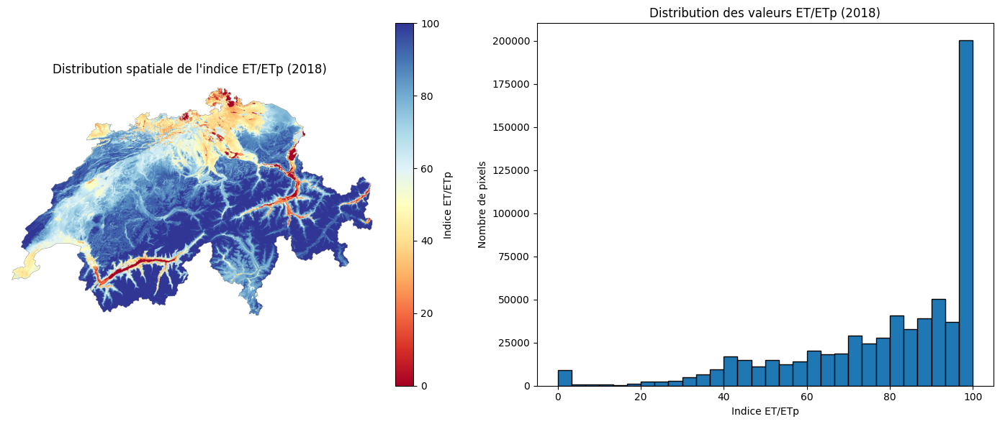

In [374]:
#Exploration de l'indice du stress hydrique

with rasterio.open(RASTER_ET_ETP) as src:
    et_etp = src.read(1, masked=True) # masquer les valeurs NoData
    extent = rasterio.plot.plotting_extent(src)

# Statistiques descriptives
print("Résolution :", src.res)
print(f"Valeur minimale : {et_etp.min()}")
print(f"Valeur maximale : {et_etp.max()}")
print(f"Moyenne : {et_etp.mean():.3f}")
print(f"Médiane : {np.ma.median(et_etp)}")
print(f"Écart-type : {et_etp.std():.3f}")

# Carte et histogramme côte à côte
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Carte du raster
im = ax[0].imshow(et_etp,cmap="RdYlBu",extent=extent,origin="upper")

fig.colorbar(im, ax=ax[0], label="Indice ET/ETp")
ax[0].set_title("Distribution spatiale de l'indice ET/ETp (2018)")
ax[0].set_xlabel("Coordonnée Est (m)")
ax[0].set_ylabel("Coordonnée Nord (m)")
ax[0].set_axis_off()

# Histogramme
ax[1].hist(et_etp.compressed(), bins=30, edgecolor="black")
ax[1].set_title("Distribution des valeurs ET/ETp (2018)")
ax[1].set_xlabel("Indice ET/ETp")
ax[1].set_ylabel("Nombre de pixels")

plt.tight_layout()
plt.show()


### **3.2 Variables explicatives**
### **3.2.1 Visualisation des données**

La couche `source_couverture_du_sol` (TLM_BODENBEDECKUNG) de swissTLM3D contient un attribut `OBJEKTART` qui identifie les différentes catégories de couverture du sol à l'aide de codes numériques. Afin de faciliter l'interprétation des données et leur représentation cartographique, une correspondance entre ces codes et leurs désignations en français a été établie à partir du Catalogue des objets swissTLM3D publié par swisstopo.

Les désignations correspondantes sont ajoutées dans une nouvelle colonne `OBJEKTART_nom`, tout en conservant les codes originaux.

In [375]:
correspondance_metadonnes= {
    1: "Falaise",
    2: "Falaise diffuse",
    3: "Blocs rocheux",
    4: "Blocs rocheux diffus",
    5: "Cours d'eau",
    6: "Forêt buissonnante",
    7: "Roches meubles",
    8: "Roches meubles diffuses",
    9: "Glacier",
    10: "Eaux stagnantes",
    11: "Zone humide",
    12: "Forêt",
    13: "Forêt clairsemée",
    14: "Surface boisée"
}
source_couverture_du_sol["OBJEKTART_nom"] = (
    source_couverture_du_sol["OBJEKTART"].map(correspondance_metadonnes)
)

source_couverture_du_sol["OBJEKTART_nom"].value_counts()


,count
OBJEKTART_nom,
Surface boisée,227563
Falaise,190002
Roches meubles,127527
Forêt,104828
Falaise diffuse,34838
Roches meubles diffuses,32586
Forêt buissonnante,31772
Forêt clairsemée,21062
Eaux stagnantes,17242


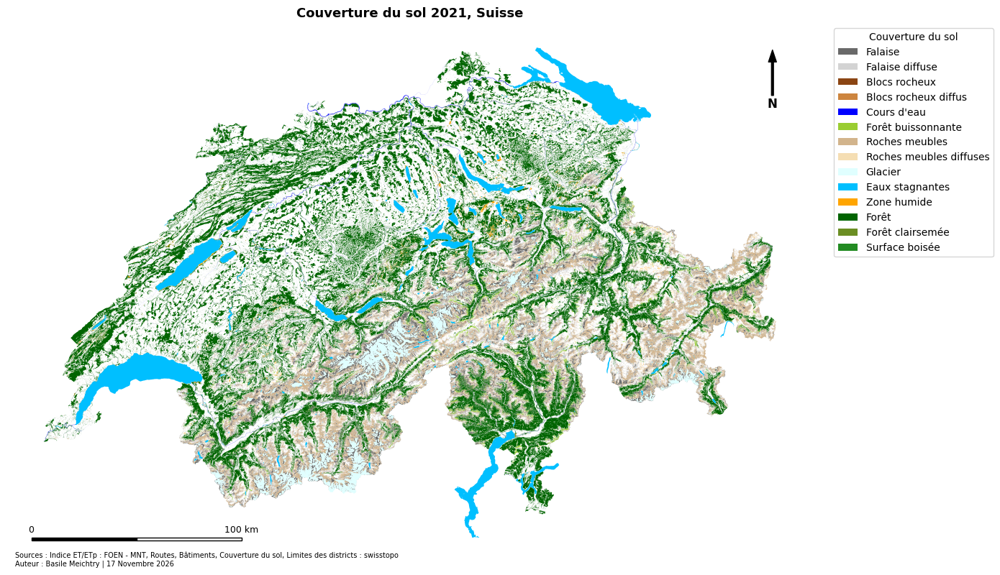

In [395]:
#Plot de la couverture du sol
couleurs = {
    "Falaise": "dimgray",
    "Falaise diffuse": "lightgray",
    "Blocs rocheux": "saddlebrown",
    "Blocs rocheux diffus": "peru",
    "Cours d'eau": "blue",
    "Forêt buissonnante": "yellowgreen",
    "Roches meubles": "tan",
    "Roches meubles diffuses": "wheat",
    "Glacier": "lightcyan",
    "Eaux stagnantes": "deepskyblue",
    "Zone humide": "orange",
    "Forêt": "darkgreen",
    "Forêt clairsemée": "olivedrab",
    "Surface boisée": "forestgreen"
}

fig, ax = plt.subplots(figsize=(14, 10))

for categorie, couleur in couleurs.items():
    source_couverture_du_sol[
        source_couverture_du_sol["OBJEKTART_nom"] == categorie
    ].plot(ax=ax, color=couleur, label=categorie)

ax.legend(title="Couverture du sol", bbox_to_anchor=(1.02, 1))
ax.set_title("Couverture du sol 2021, Suisse",fontsize=13, fontweight='bold')
ax.set_axis_off()
fleche_nord(ax)
infos_carte(ax)
echelle(ax, longueur_km=100)

plt.tight_layout()
plt.show()

Districts sélectionnés : ['Hérens', 'Sierre', 'Conthey', 'Sion']
Nombre de districts : 4


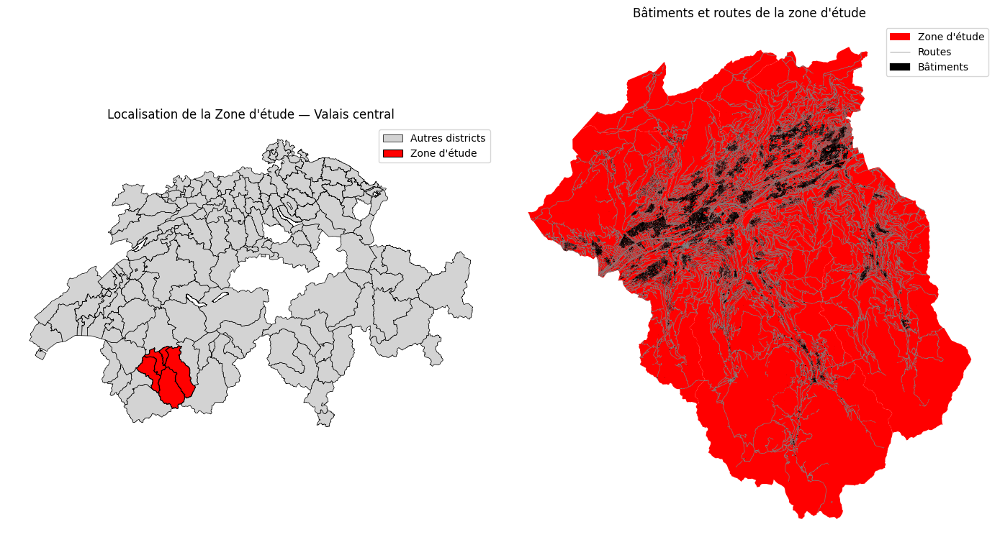

In [377]:
#Visualisation de la zone d'étude

# Sélectionner les quatre districts
districts_etude = source_limite_districts[source_limite_districts["NAME"].isin([ "Sion","Hérens","Conthey","Sierre"])].copy()
# Vérifier la sélection
print("Districts sélectionnés :", districts_etude["NAME"].tolist())
print("Nombre de districts :", len(districts_etude))

# Fusionner les districts pour obtenir une seule zone
zone_etude = districts_etude.dissolve()

# Créer une figure
fig, ax = plt.subplots(1,2, figsize=(14, 8))


# Tous les districts en gris
source_limite_districts.plot(ax=ax[0],color="lightgrey",edgecolor="black",linewidth=0.5,label="Autres districts")

# Les quatre districts de la zone d'étude en jaune
districts_etude.plot(ax=ax[0],color="red",edgecolor="black",linewidth=0.8,label="Zone d'étude")

#Visualisation des batiments et des routes
districts_etude.plot(ax=ax[1],color="red",linewidth=0.8,label="Zone d'étude",zorder=1)
source_routes_clip.plot(ax=ax[1],color="gray",linewidth=0.5,label="Routes", zorder=2)
source_batiments_clip.plot(ax=ax[1],facecolor="black",edgecolor="black",linewidth=0.2,label="Bâtiments",zorder=3)



# Légende
ax[0].set_title("Localisation de la Zone d'étude — Valais central")
ax[0].set_axis_off()
ax[0].legend()
ax[1].set_title("Bâtiments et routes de la zone d'étude")
ax[1].set_axis_off()
ax[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

Nous allons à présent visualiser les deux premières variables explicatives, l'altitude et la pente.

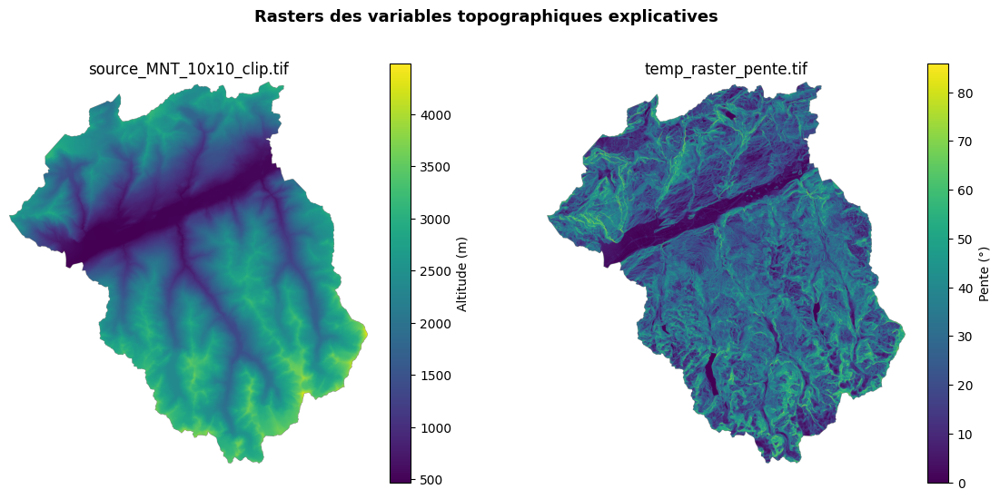

In [378]:
#Visualisation du MNT et de la pente

with rasterio.open(RASTER_MNT) as src:
    mnt = src.read(1,masked= True)
with rasterio.open(RASTER_Pente) as src:
    pente = src.read(1,masked=True)


fig, ax = plt.subplots(1, 2, figsize=(14, 6))

im1=ax[0].imshow(mnt, cmap='viridis')
ax[0].set_title("source_MNT_10x10_clip.tif")
ax[0].set_axis_off()
fig.colorbar(im1, ax=ax[0], label="Altitude (m)")


im2=ax[1].imshow(pente, cmap='viridis', label="Pente (°)")
ax[1].set_title("temp_raster_pente.tif")
ax[1].set_axis_off()
fig.colorbar(im2, ax=ax[1], label="Pente (°)")

fig.suptitle('Rasters des variables topographiques explicatives', fontsize=13, fontweight='bold')
plt.show()




### **3.2.2. Stress hydrique et Urbanisation**

In [379]:
#Visualisation du stress hydrique, des batiments et des routes sur le meme plot.

# Ouvrir le raster ET/ETp
with rasterio.open(RASTER_ET_ETP) as src:

    # Récupérer les géométries de chaque district
    geometries = [mapping(geom) for geom in districts_etude.geometry if geom is not None and not geom.is_empty]

    # Découper le raster
    et_etp_clip, transform = mask(src,geometries, crop=True,filled=False)

# Calculer l'emprise du raster découpé
height, width = et_etp_clip.shape[-2:]
bounds = array_bounds(height, width, transform)

extent_clip = (
    bounds[0], bounds[2],
    bounds[1], bounds[3]
)

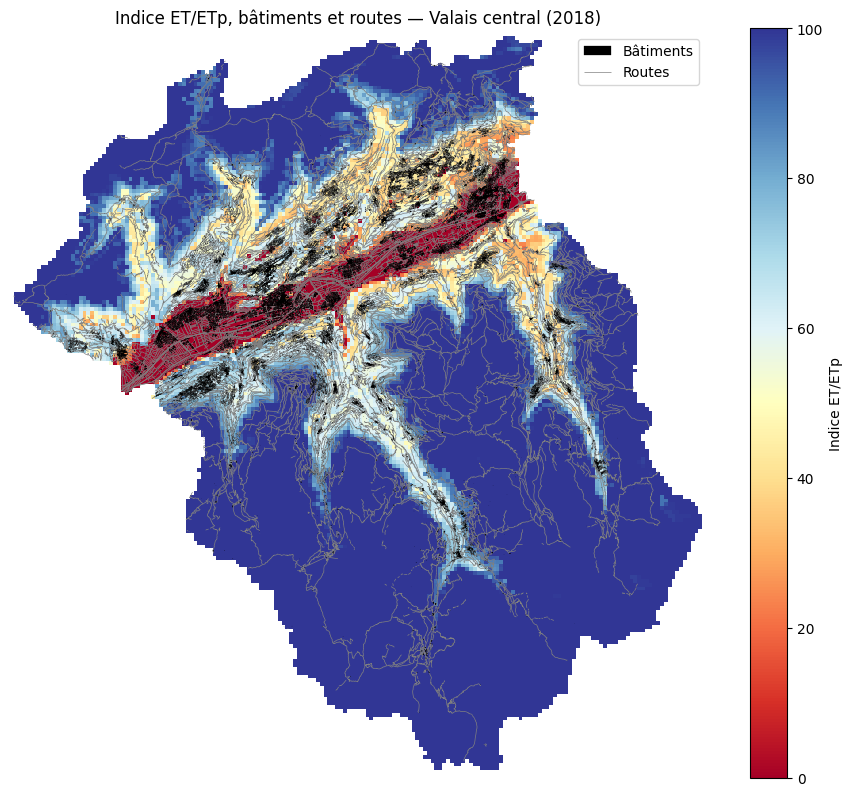

In [380]:
fig, ax = plt.subplots(figsize=(9, 8))

# Raster ET/ETp
im = ax.imshow(et_etp_clip[0],cmap="RdYlBu",extent=extent_clip,origin="upper")

# Bâtiments et routes
source_batiments_clip.plot(ax=ax,facecolor="black",edgecolor="black",linewidth=0.2,label="Bâtiments",zorder=3)
source_routes_clip.plot(ax=ax,color="grey",linewidth=0.5,label="Routes",zorder=2)

# Colorbar
fig.colorbar(im, ax=ax, label="Indice ET/ETp")
ax.set_title("Indice ET/ETp, bâtiments et routes — Valais central (2018)")
ax.set_xlabel("Coordonnée Est (m)")
ax.set_ylabel("Coordonnée Nord (m)")
ax.set_axis_off()

# Légende
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

On observe que les secteurs où les bâtiments et les routes sont particulièrement concentrés présentent généralement des valeurs plus faibles de l'indice ET/ETp. Cette relation est purement visuelle et motive la suite du projet, consacrée à l'analyse statistique de ces relations. Nous allons en effet calculer la densité urbaine et la distance à la zone urbaine la plus proche pour chaque pixel forestier (§4) pour obtenir les deux dernières variables explicatives.

---
## 4. Chaîne de pré-traitements : des données sources au tableau d'analyse

De nombreuses opérations sont nécessaire pour dériver le tableau d'analyse depuis les données sources. Celles-ci sont résumées ci-dessous avec la convention suivante: ovales bleus pour les données sources, rectangles jaunes pour les opérations de géotraitement, ovales verts pour les données transformées.

In [381]:
display(Image(filename=chaine_traitements))

Cette chaîne de géotraitements a entièrement été réalisée dans QGIS à l'aide du modeleur graphique. Le fichier correspondant `Stress_hydrique.model3` est fourni dans l'archive.

### **4.1 Justification des étapes**

1. **Polygonisation du Raster ET/ETp** <br>
Le raster ET/ETP est polygonisé afin de transformer les cellules de la grille raster en entités vectorielles. Cette opération permet d'obtenir une représentation vectorielle de la grille de 250 × 250 m et d'utiliser les cellules comme unités spatiales pour les opérations de géotraitement ultérieures. La valeur ET/ETP est conservée comme attribut des entités.<br>
Cette étape est effectuée avec l'outil natif de QGIS "Pixels de raster en polygones", qui ne crée pas automatiquement d'indice unique pour chaque pixel. Ceci est résolu par l'étape supplémentaire "Ajouter un champ auto-incrémenté", qui ajoute le champ `id_pixel`

2. **Sélection des surfaces forestières**<br>
L'opération "Extraire par expression" sur la couche `source_Couverture_du_sol`  permet de sélectionner les catégories correspondant aux surfaces forestières à partir de l'attribut `OBJEKTART`. Les codes 6, 12, 13 et 14 correspondent respectivement à la forêt buissonnante, la forêt, la forêt clairsemée et la surface boisée selon le Catalogue des objets swissTLM3D publié par swisstopo.


3. **Délimitation de la zone d'étude et découpage** <br>
Pour définir la zone d'étude au Valais Central, l'outil "Extraire par expression" a été utilisé sur la couche `source_limites_districts` , avec cette commande: `"NAME" IN ('Hérens', 'Sierre', 'Sion', 'Conthey')`.
Ensuite, les couches des bâtiments, des routes, des surfaces forestières, le MNT et la grille de 250x250 sont découpées à la zone d'étude à l'aide de l'outil "Couper".

4. **Calcul de la pente et statistiques zonales de l'altitude et de la pente**<br>
L'outil GDAL "Pente" permet de calculer la pente (`temp_raster_pente`) à partir du MNT initial, avec la même résolution (10x10m).<br><br>
La grille ET/Etp de 250x250m et les rasters de pente et d'altitude (MNT) n'ont donc pas la même résolution. L'outil "Statistiques de zone" permet d'agréger les informations de ces deux rasters à l'échelle de la grille de 250x250m en calculant leur moyenne pour chacun des pixel de cette grille.

5. **Sélection des pixels avec plus de 25 % de couverture forestière**<br>
Après avoir effectué l’intersection entre la grille de 250 × 250 m et les surfaces forestières, la calculatrice de champ permet de calculer la surface forestière présente dans chaque pixel. L’outil « Extraire par expression » est ensuite utilisé pour sélectionner uniquement les pixels dont la surface forestière est supérieure ou égale à 15 625 m² ("sum" >= 15625), ce qui correspond à au moins 25 % de la surface totale d’un pixel (62 500 m²). Ce seuil permet de retenir les pixels présentant une couverture forestière suffisamment importante pour être intégrés à l’analyse, sans exiger qu’ils soient entièrement recouverts de forêt.

6. **Buffers et création de la Zone urbaine**<br>
Afin de délimiter les zones urbanisées, des Buffer sont appliqués aux couches des routes et des bâtiments. Pour les routes, on suppose leur largeur à environ 12m, on applique donc un buffer de 6m. Pour les bâtiments, on applique deux buffers successifs, +75m puis -75m afin de regrouper les bâtiments proches en une zone continue.
Les couches sont ensuite fusionées avec l'outil "Union" puis "Dissoudre" pour obtenir une seule géometrie représentant la Zone urbaine.

7. **Calcul de la densité urbaine et de la distance aux zones urbanisées** <br>
La densité urbaine est calculée pour chaque pixel de la grille de 250x250 m à partir de la surface urbaine obtenue après intersection entre la zone urbaine et la grille. La calculatrice de champ permet de calculer le pourcentage de surface urbanisée dans chaque pixel à l'aide de l'expression `coalesce("surf_urb", 0) / 62500 * 100`, ou 62500 correspond à la surface total d'un pixel de 250x250m.<br>
La distance aux zones urbanisées est calculée à l'aide de l'outil "Joindre les attributs par le plus proche". Les centroïdes des pixels forestiers sont utilisé comme point de référence pour le calcul de cette distance.

Les buffers permettent de prendre en compte l'espace autour des routes et des bâtiments. Ils peuvent donc inclure des surfaces forestières ou naturelles dans la zone urbaine. La densité calculée représente ainsi la proportion du pixel incluse dans cette zone, et pas uniquement la surface réellement construite. Cela explique pourquoi certains pixels peuvent présenter à la fois une couverture forestière importante et une densité urbaine élevée.

### **4.2 Tableau d'analyse**<br>

L'ensemble des traitements précédents permet d'obtenir la couche `input_grille_analyse`. Celle-ci contient la grille des pixels de 250x250m et d'au moins 25% de surface forestière. Pour chacun de ces pixels, on y retrouve la valeur de l'indice hydrique ET/ETp, la pente (°) et l'altitude (m) moyenne calculées à partir du MNT, la densité urbaine (%) et la distance (m) du centroïde du pixel par rapport à la zone urbaine la plus proche.<br>
Cette couche constitue la table d'entrée de la régression linéaire.




In [382]:
input_grille_analyse =gpd.read_file(GPKG, layer="input_grille_analyse")
input_grille_analyse[['ET/ETp','pentemean','altitudemean','dens_urb','distance']].head()

,ET/ETp,pentemean,altitudemean,dens_urb,distance
0,88.0,38.036349,1973.658822,6.547,31.820178
1,82.0,14.226759,1821.416406,5.682,45.252820
2,83.0,17.612515,1813.659810,17.932,19.289301
3,71.0,9.858682,1820.220262,7.027,73.935190
4,77.0,12.221063,1798.839399,13.956,20.759706


Tableau d'analyse: 6425 pixels forestiers retenus


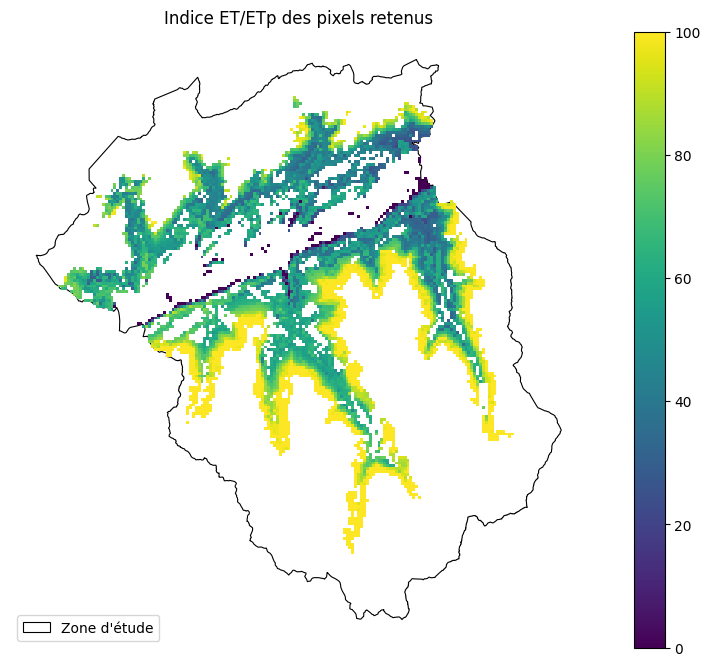

In [383]:
print(f"Tableau d'analyse: {len(input_grille_analyse)} pixels forestiers retenus")

fig, ax = plt.subplots(figsize=(12, 8))
zone_etude.plot(ax=ax,color="none",edgecolor="black",linewidth=0.8,label="Zone d'étude")
input_grille_analyse.plot(column='ET/ETp',ax=ax,legend=True)
ax.set_axis_off()
ax.set_title("Indice ET/ETp des pixels retenus", loc='center')
ax.legend(loc='lower left')
plt.tight_layout
plt.show()


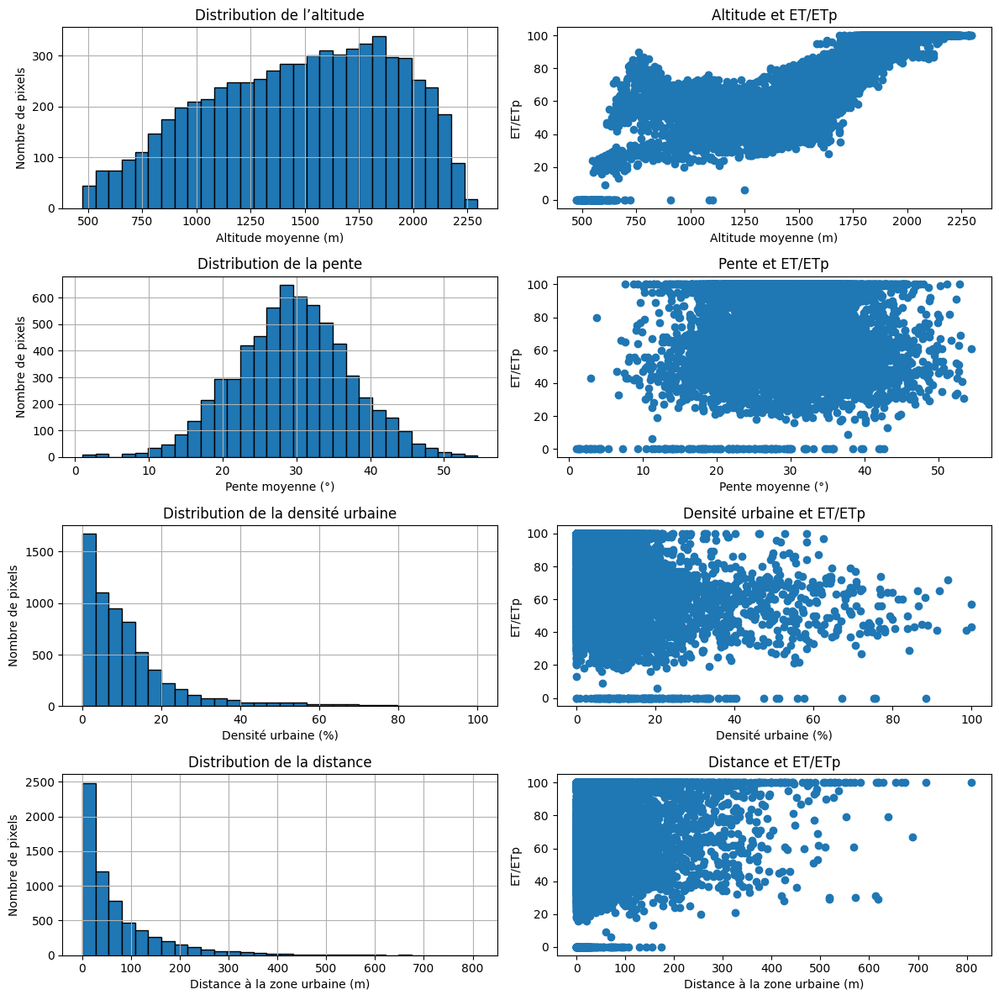

In [384]:
fig, ax = plt.subplots(4, 2, figsize=(12, 12))

# Altitude
input_grille_analyse['altitudemean'].hist(ax=ax[0,0], bins=30, edgecolor='black')
ax[0,0].set_title('Distribution de l’altitude')
ax[0,0].set_xlabel('Altitude moyenne (m)')
ax[0,0].set_ylabel('Nombre de pixels')

ax[0,1].scatter(input_grille_analyse['altitudemean'], input_grille_analyse['ET/ETp'])
ax[0,1].set_title('Altitude et ET/ETp')
ax[0,1].set_xlabel('Altitude moyenne (m)')
ax[0,1].set_ylabel('ET/ETp')

# Pente
input_grille_analyse['pentemean'].hist(ax=ax[1,0], bins=30, edgecolor='black')
ax[1,0].set_title('Distribution de la pente')
ax[1,0].set_xlabel('Pente moyenne (°)')
ax[1,0].set_ylabel('Nombre de pixels')

ax[1,1].scatter(input_grille_analyse['pentemean'], input_grille_analyse['ET/ETp'])
ax[1,1].set_title('Pente et ET/ETp')
ax[1,1].set_xlabel('Pente moyenne (°)')
ax[1,1].set_ylabel('ET/ETp')


# Densité urbaine
input_grille_analyse['dens_urb'].hist(ax=ax[2,0], bins=30, edgecolor='black')
ax[2,0].set_title('Distribution de la densité urbaine')
ax[2,0].set_xlabel('Densité urbaine (%)')
ax[2,0].set_ylabel('Nombre de pixels')

ax[2,1].scatter(input_grille_analyse['dens_urb'], input_grille_analyse['ET/ETp'])
ax[2,1].set_title('Densité urbaine et ET/ETp')
ax[2,1].set_xlabel('Densité urbaine (%)')
ax[2,1].set_ylabel('ET/ETp')


# Distance
input_grille_analyse['distance'].hist(ax=ax[3,0], bins=30, edgecolor='black')
ax[3,0].set_title('Distribution de la distance')
ax[3,0].set_xlabel('Distance à la zone urbaine (m)')
ax[3,0].set_ylabel('Nombre de pixels')

ax[3,1].scatter(input_grille_analyse['distance'], input_grille_analyse['ET/ETp'])
ax[3,1].set_title('Distance et ET/ETp')
ax[3,1].set_xlabel('Distance à la zone urbaine (m)')
ax[3,1].set_ylabel('ET/ETp')

plt.tight_layout()
plt.show()



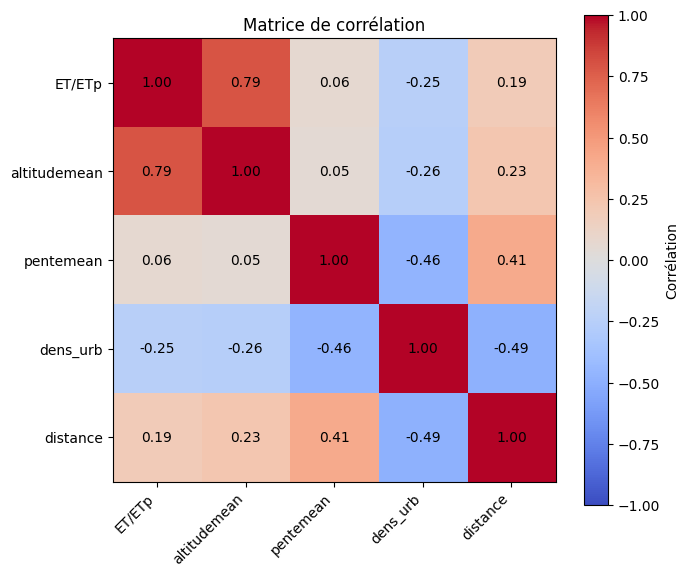

In [385]:
# Sélection des variables
donnees = input_grille_analyse[
    ['ET/ETp', 'altitudemean', 'pentemean', 'dens_urb', 'distance']
]

# Calcul de la matrice de corrélation
matrice_corr = donnees.corr()

# Affichage
fig, ax = plt.subplots(figsize=(7, 6))

image = ax.imshow(matrice_corr, cmap='coolwarm', vmin=-1, vmax=1)

ax.set_xticks(range(len(matrice_corr.columns)))
ax.set_yticks(range(len(matrice_corr.columns)))

ax.set_xticklabels(matrice_corr.columns, rotation=45, ha='right')
ax.set_yticklabels(matrice_corr.columns)

for i in range(len(matrice_corr)):
    for j in range(len(matrice_corr)):
        ax.text(j, i, f'{matrice_corr.iloc[i, j]:.2f}',
                ha='center', va='center')

fig.colorbar(image, ax=ax, label='Corrélation')
ax.set_title('Matrice de corrélation')
plt.tight_layout()
plt.show()

Des nuages de points ont été réalisés afin d'examiner les relations entre le rapport ET/ETp et les différentes variables explicatives individuellement. L'altitude présente une tendance globalement positive avec ET/ETp, bien que la relation ne soit pas strictement linéaire. Pour la pente, la densité urbaine et la distance aux zones urbanisées, les observations sont fortement dispersées et aucune tendance linéaire claire ne se dégage visuellement.

On observe sur la matrice de corrélation que l'altitude présente la plus forte corrélation avec ET/ETp, tandis que les autres variables montrent des corrélations nettement plus faible. Ce résultat suggère que l'altitude pourrait jouer un rôle important dans la prédiction du rapport ET/ETp.

Ces observations permettent de mieux comprendre les relations entre les variables avant la modélisation. Une régression linéaire multiple est retenue afin d'évaluer la contribution combinée des caractéristiques topographiques et de l'urbanisation à la prédiction de ET/ETp. La pertinence du modèle sera ensuite évaluée à partir de ses performances prédictives et de l'analyse de ses résidus.

---
## 5. Modélisation : ajustement, évaluation et choix du modèle

L'objectif de cette étude est de prédire les variations spatiales de l'indice ET/ETp dans les surfaces forestières du Valais central à partir de caractéristiques topographiques et des propriétés de l'urbanisation environnante. Pour cela, un modèle de régression linéaire multiple sera utilisé. Ce choix se justifie par la nature continue de la variable à expliquer, l'indice ET/ETp, dont on cherche à prédire la valeur pour chaque pixel forestier. De plus, ce modèle permet d’évaluer la contribution respective des caractéristiques topographiques et de l’urbanisation sur les prédictions.

Afin d'évaluer l'apport des variables liées à l'urbanisation, **deux modèles seront comparés**:
- Modèle 1 – Relief : utilise uniquement l'altitude et la pente comme variables explicatives.
- Modèle 2 – Relief et urbanisation : intègre les quatre variables explicatives, soit l'altitude, la pente, la densité urbaine et la distance aux zones urbanisées.

Afin d'évaluer la fiabilité des modèles, les pixels forestiers seront répartis en deux groupes. Le premier servira à entraîner les modèles, tandis que le second permettra de tester leurs prédictions. Pour cela, les valeurs d'ET/ETp prédites seront comparées aux valeurs réelles de ces mêmes pixels. Les performances des modèles seront évaluées à l'aide du coefficient de détermination (R²), du RMSE (erreur quadratique moyenne) et du MAE (erreur absolue moyenne).  Ces indicateurs permettront de quantifier les erreurs de prédiction et de déterminer lequel des deux modèles fournit les meilleurs résultats.


### **5.1 Séparation des données d'entraînement et de test**

Une séparation spatiale des données est privilégiée plutôt qu'une séparation aléatoire pour entraîner et évaluer les modèles. En effet, les pixels voisins peuvent présenter des caractéristiques toopographiques et environnementales similaires et des valeurs d'ET/ETp proches. Cette proximité peut aider implicitement les modèles.

La séparation spatiale permet donc d'évaluer plus rigoureusement la capacité des modèles à prédire le rapport ET/ETp dans des secteurs géographiques qui n'ont pas été utilisés lors de l'entraînement.

La zone d'étude sera divisée en blocs spatiaux de 2x2km. Les blocs sont ensuite répartis entre les ensembles d'entraînement (80%) et de test (20%). Les modèles seront ainsi évalués sur des secteurs géographiques qui n'ont pas été utilisés lors de l'entraînement.

In [386]:
#Taille des blocs en mètres
Taille_bloc = 2000

#calcul des centroïdes des pixels (pour éviter le chevauchement des pixels entre les blocs)
centroides= input_grille_analyse.geometry.centroid

#Identifiant pour chaque bloc
bloc = (
    (centroides.x // Taille_bloc).astype(int).astype(str)
    + '_'
    + (centroides.y // Taille_bloc).astype(int).astype(str)
)

# Liste des blocs uniques
blocs = np.unique(bloc)

# Mélange aléatoire des blocs
rng = np.random.default_rng(SEED)
blocs_aleatoires = rng.permutation(blocs)

# Séparation des blocs
limite = int(len(blocs) * 0.8)

blocs_train = blocs_aleatoires[:limite]
blocs_test = blocs_aleatoires[limite:]

Pixels entraînement : 5221
Pixels test : 1204


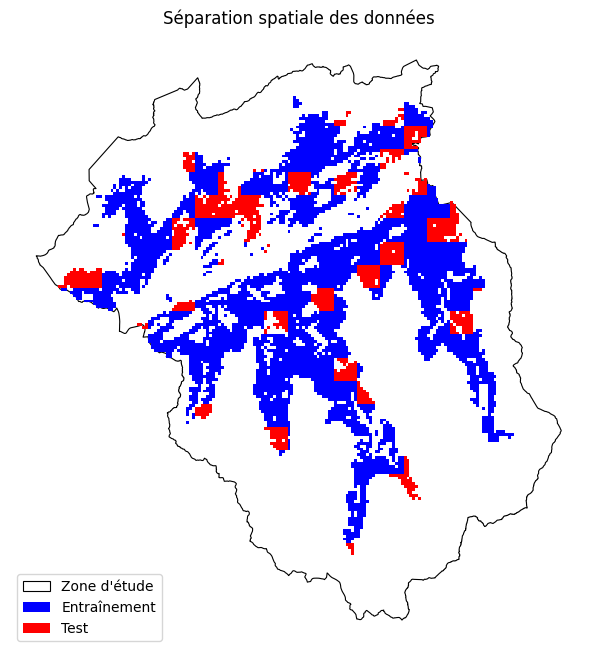

In [387]:
train = bloc.isin(blocs_train)
test = bloc.isin(blocs_test)
print("Pixels entraînement :", train.sum())
print("Pixels test :", test.sum())

fig, ax = plt.subplots(figsize=(10,8))
zone_etude.plot(ax=ax,color="none",edgecolor="black",linewidth=0.8,label="Zone d'étude")
input_grille_analyse[train].plot(ax=ax, color='blue', label='Entraînement')

input_grille_analyse[test].plot( ax=ax, color='red', label='Test')

ax.set_title("Séparation spatiale des données")
ax.legend(loc= 'lower left')
ax.set_axis_off()

plt.show()


### **5.2 Entraînement du modèle**

In [388]:
# Préparation des données

# Variable à prédire
y = input_grille_analyse['ET/ETp']

# Variables explicatives du modèle 1
X1 = input_grille_analyse[['altitudemean', 'pentemean']]

# Variables explicatives du modèle 2
X2 = input_grille_analyse[['altitudemean', 'pentemean', 'dens_urb', 'distance']]

# Modèle 1 : relief
X1_train = X1[train]
X1_test = X1[test]

# Modèle 2 : relief + urbanisation
X2_train = X2[train]
X2_test = X2[test]

# Variable à prédire
y_train = y[train]
y_test = y[test]

In [389]:
# Modèle 1 : relief
modele1 = LinearRegression().fit(X1_train, y_train)

# Modèle 2 : relief + urbanisation
modele2 = LinearRegression().fit(X2_train, y_train)

# Prédictions du modèle 1
y_pred1 = modele1.predict(X1_test)

# Prédictions du modèle 2
y_pred2 = modele2.predict(X2_test)

### **5.3 Calcul des métriques et benchmarking**

In [390]:
#Benchmark
y_pred_benchmark=np.full_like(y_test, y_train.mean())
print("Benchmark")
print(f"R² : {r2_score(y_test, y_pred_benchmark):.3f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, y_pred_benchmark)):.3f}")
print(f"MAE : {mean_absolute_error(y_test, y_pred_benchmark):.3f}")

# Modèle 1
print("\nModèle 1 - Relief")
print(f"R² : {r2_score(y_test, y_pred1):.3f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, y_pred1)):.3f}")
print(f"MAE : {mean_absolute_error(y_test, y_pred1):.3f}")

# Modèle 2
print(f"\nModèle 2 - Relief + urbanisation")
print(f"R² : {r2_score(y_test, y_pred2):.3f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, y_pred2)):.3f}")
print(f"MAE : {mean_absolute_error(y_test, y_pred2):.3f}")

Benchmark
R² : -0.015
RMSE : 26.375
MAE : 22.139

Modèle 1 - Relief
R² : 0.655
RMSE : 15.370
MAE : 12.123

Modèle 2 - Relief + urbanisation
R² : 0.656
RMSE : 15.342
MAE : 12.117


### **5.4 Choix du modèle et importance des variables**

Les résultats de la modélisation confirment en partie les observations issues de l'analyse exploratoire des données. Les deux modèles présentent des performances nettement supérieures au benchmark qui prédit systématiquement la moyenne du rapport ET/ETp calculé sur le jeu d'entraînement. Le modèle 1 obtient un R² de  0.655 contre -0.015 pour le benchmark, ce qui indique que les variables topographiques apportent une information prédictive importante.

L'intégration de variables liées à l'urbanisation dans le modèle 2 entraîne toutefois une amélioration **minime** des performances, avec un R² augmentant de 0.655 à 0.656 et une très légère diminution des erreurs de prédiction (RMSE de 15.370 à 15.342 et MAE de 12.123 à 12.117).

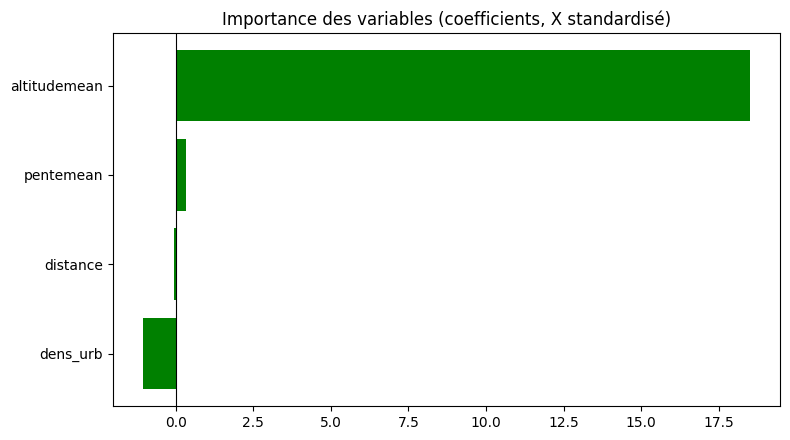

dens_urb : -1.059
distance : -0.069
pentemean : 0.329
altitudemean : 18.496


In [391]:
# Standardisation des variables explicatives
scaler = StandardScaler()
X2_train_std = scaler.fit_transform(X2_train)

# Modèle standardisé
modele2_std = LinearRegression().fit(X2_train_std, y_train)

# Coefficients
coefficients = pd.Series(modele2_std.coef_,index=X2.columns).sort_values()

# Graphique
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.barh(coefficients.index, coefficients.values, color='green')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Importance des variables (coefficients, X standardisé)')
plt.tight_layout()
plt.show()
for variable, valeur in coefficients.items():
    print(f"{variable} : {valeur:.3f}")

Les variables explicatives du modèle 2 ont été standardisées afin de rendre leurs échelles comparables. Les coefficients de la régression permettent ainsi de comparer leur contribution respective à la prédiction du rapport ET/ETp. L'altitude a le coefficient le plus élevé (+18.496), ce qui indique qu'elle constitue la variable la plus importante de la régression linéaire: les pixels forestiers de plus haute altitude présentent généralement un rapport ET/ETp plus important. La densité urbaine présente un coefficient négatif (-1.059): une augmentation de la densité urbaine est associée à une diminution du rapport ET/ETp. La pente (+0.329) et la distance (-0.069) présentent des coefficients beaucoup plus faible.

Le **modèle 2** est retenu pour la suite de l'analyse car il présente les meilleures performances parmis les deux modèles comparés et permet de prendre en compte à la fois les caractéristiques topographiques et le contexte d'urbanisation. Toutefois, le gain prédictif apporté par les variables urbaines reste faible. Ces résultats ne permettent donc pas de conclure à une influence négligeable de l'urbanisation sur le stress hydrique, mais indiquent que son apport prédictif est limité dans le cadre du modèle linéaire considéré.

---
## 6. Analyse des résidus

Dans le cadre de la régression linéaire retenue, les résidus correspondent à la différence entre les valeurs réelles du rapport ET/ETp et les valeurs prédites par le modèle 2 pour un pixel i: $e_i = y_i - \hat{y}_i$. Un résidu est positif quand le modèle a sous-estimé la valeur réelle, tandis qu'un résidu négatif indique qu'il l'a surestimée. Un résidu proche de zéro traduit une faible erreur de prédiction.
On calcul les résidus de la régression linéaire sur les données de test qui n'ont pas servies à entraîner le modèle pour éviter des résutats artificiellement optimistes.

In [392]:
residus = y_test - y_pred2
print(f"Moyenne des résidus : {residus.mean():.3f}")
print(f"Ecart-type des résidus : {residus.std():.3f}")
print(f"Min des résidus : {residus.min():.3f}")
print(f"Max des résidus : {residus.max():.3f}")

Moyenne des résidus : -2.383
Ecart-type des résidus : 15.162
Min des résidus : -36.828
Max des résidus : 47.924


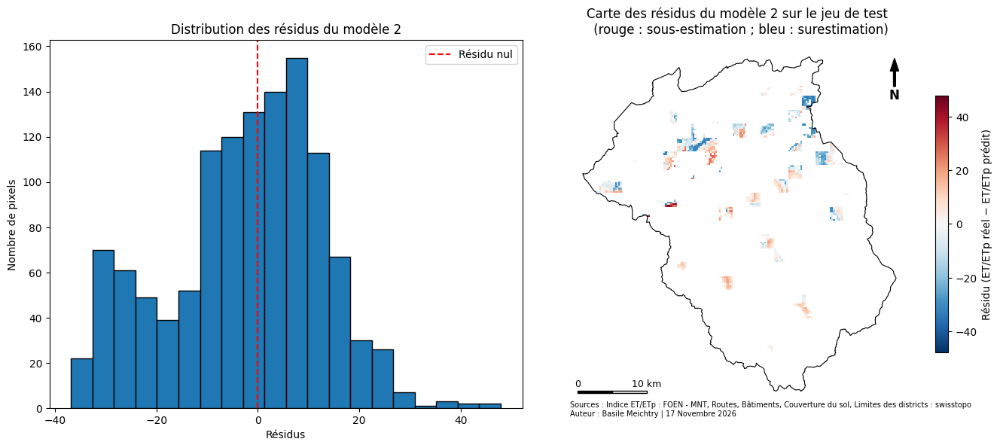

In [393]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Histogramme des résidus
ax[0].hist(residus, bins=20, edgecolor='black')
ax[0].axvline(0, color='red', linestyle='--', label='Résidu nul')

ax[0].set_title('Distribution des résidus du modèle 2')
ax[0].set_xlabel('Résidus')
ax[0].set_ylabel('Nombre de pixels')
ax[0].legend()

# Ajouter les résidus à la couche des pixels de test
carte_residus = input_grille_analyse.loc[test].copy()
carte_residus['residus'] = residus

# Colorbar symmétrique autour de zéro
limite = np.abs(residus).max()

# Carte des résidus
carte_residus.plot(column='residus',ax=ax[1],cmap='RdBu_r',vmin=-limite,vmax=limite,legend=True,legend_kwds={'label': 'Résidu (ET/ETp réel − ET/ETp prédit)','shrink': 0.7})

# Zone d'étude
zone_etude.boundary.plot(ax=ax[1], color='black', linewidth=0.8)
ax[1].set_title("Carte des résidus du modèle 2 sur le jeu de test \n (rouge : sous-estimation ; bleu : surestimation)")
ax[1].set_axis_off()
fleche_nord(ax[1])
infos_carte(ax[1])
echelle(ax[1])
plt.tight_layout()
plt.show()

L'analyse de la distribution des résidus montre que ceux-ci sont globalement centrés autour de zéro, indiquant l'absence de biais sysématique. Cependant, on observe une bosse autour de -30, suggérant qu'un sous-groupe d'observations est systématiquement surestimé par le modèle.

La carte des résidus permet de mieux comprendre cette hétérogénéité: les erreurs ne sont pas uniformément réparties dans la zone d'étude. Certains regroupements locaux de résidus positifs et négatifs sont observables, suggérant que le modèle ne reproduit pas parfaitement les variations spatiales de l'indice ET/ETp. Ces écarts localisés pourraient s'expliquer par une structure spatiale que le modèle n'arrive pas à capturer.

---
## 7. Carte des prédictions et incertitude

### **7.1 Carte des prédictions**

Les prédictions du modèle de régression linéaire retenu (le modèle 2), réalisées pour chaque pixel de la zone d'étude à partir des 4 variables explicatives, sont résumées par la carte ci-dessous.

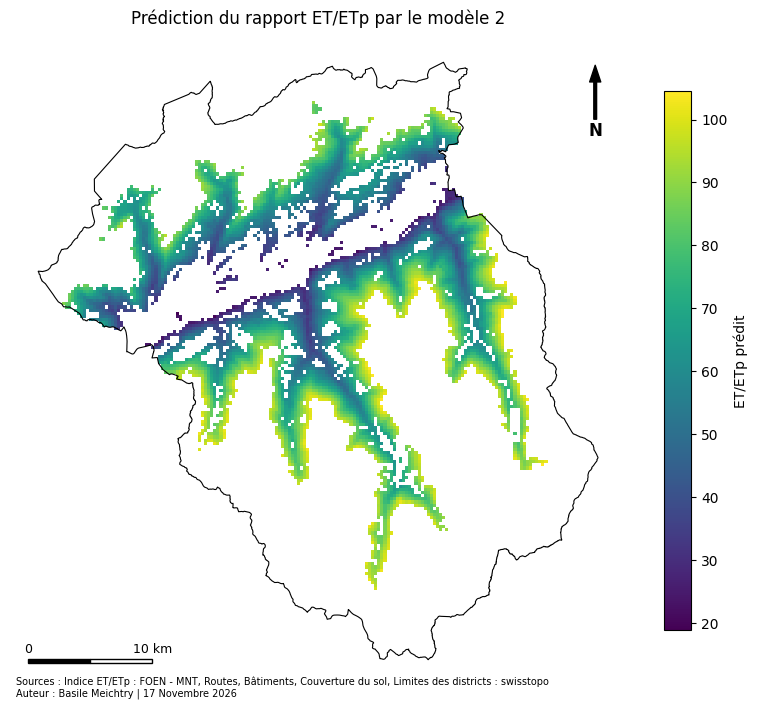

In [394]:
# Prédictions sur l'ensemble des pixels
y_pred = modele2.predict(input_grille_analyse[X2.columns])

# Ajouter les prédictions à la couche géographique
carte_predictions = input_grille_analyse.copy()
carte_predictions['ET/ETp_pred'] = y_pred
fig, ax = plt.subplots(figsize=(8, 8))

carte_predictions.plot(column='ET/ETp_pred',ax=ax,cmap='viridis',legend=True,legend_kwds={'label': 'ET/ETp prédit','shrink': 0.7})

zone_etude.boundary.plot(ax=ax, color='black', linewidth=0.8)

ax.set_title('Prédiction du rapport ET/ETp par le modèle 2', loc='center')
ax.set_axis_off()
fleche_nord(ax)
infos_carte(ax)
echelle(ax)

plt.tight_layout()
plt.show()

---
## 8. Export des résultats

---
## 9. Conclusion